# 4-2. 민감도 분석

**질문**: 우리가 정한 기준과 가정을 바꿔도 **결론이 유지되나?**
금액이 바뀌는 것은 당연하므로, 결론(어디에 할인하나 / 우리 배분이 균등보다 나은가)이 유지되는지만 본다.

| 확인 | 바꾼 것 | 결론 |
|---|---|---|
| ① 대상 선정 | 수요 필터 하위 20%·30%, 소비갭 기준 중앙값 → 평균 | 할인 배치 대상 18개 동이 유지되나 |
| ② 배분 결론 | 흡수 한도(cap) 낙관/보수 × QR 측정 방식 × 시행 계절 | 우리 배분이 균등 배분보다 많이 집행되나 |
| ③ 참고 | 타깃 국적 기준 5%·15% | 주 국적이 유지되나 |

- 효과값(0.44 / 1.10 / 2.22원)은 두 배분에 똑같이 곱해져 비교 결론이 바뀌지 않으므로 제외 (3-3에서 범위로 제시)
- 등급 가중치는 3-1, 계절별 대상 변화는 4-1 참고

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['NanumGothic', 'AppleGothic', 'Malgun Gothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False

A    = pd.read_csv('마스터_A_동.csv', encoding='utf-8-sig')
B    = pd.read_csv('마스터_B_동월.csv', encoding='utf-8-sig')
P14  = pd.read_csv('진단_2x2_처방유형.csv', encoding='utf-8-sig')
ALLOC = pd.read_csv('3-1_3-2_최종표.csv', encoding='utf-8-sig')          # 3-1·3-2 최종표 (2개월, 총예산 3억)
QR   = pd.read_csv('QR_가게단위_매칭.csv', encoding='utf-8-sig')
NAT  = pd.read_csv('1-5_민감도_국적기준.csv', encoding='utf-8-sig')

BASE = set(P14.loc[P14['처방유형'].str[0].isin(['①', '②']), '행정동명'])   # 할인 배치 대상 18개 동
TOTAL = 300_000_000
print('기준 할인 배치 대상:', len(BASE), '개 동')

## ① 대상 선정이 안정적인가
- 기본: 수요 필터 하위 25% (방문 **또는** 결제 건수가 넘으면 통과), 소비갭 기준 = 통과 동 방문당 소비 **중앙값**
- 바꾼 것: 하위 20% / 30%, 기준을 평균으로

In [ ]:
def diagnose(q=0.25, ref='median'):
    f = A[(A['방문'] > A['방문'].quantile(q)) | (A['건수_음식소매'] > A['건수_음식소매'].quantile(q))]
    line = f['방문당소비_음식소매'].median() if ref == 'median' else f['방문당소비_음식소매'].mean()
    return set(f.loc[f['방문당소비_음식소매'] < line, '행정동명']), len(f), line

rows = []
for label, kw in [('기본 (하위 25%, 중앙값)', {}), ('수요 필터 하위 20%', dict(q=0.20)),
                  ('수요 필터 하위 30%', dict(q=0.30)), ('소비갭 기준 평균', dict(ref='mean'))]:
    s, n, line = diagnose(**kw)
    rows.append({'조건': label, '수요 필터 통과': n, '소비갭 기준선(원)': round(line),
                 '할인 배치 대상': len(s), '기존 18개 중 유지': len(BASE & s),
                 '빠진 동': ', '.join(sorted(BASE - s)) or '-', '추가된 동': ', '.join(sorted(s - BASE)) or '-'})
SEL = pd.DataFrame(rows)
with pd.option_context('display.max_colwidth', None):
    display(SEL)
SEL.to_csv('4-2_대상선정_민감도.csv', index=False, encoding='utf-8-sig')

top = A.nlargest(3, '방문당소비_음식소매')[['행정동명', '방문당소비_음식소매']]
print('방문당 소비 상위 3개 동 (평균을 끌어올리는 극단값):')
print(top.assign(방문당소비_음식소매=top['방문당소비_음식소매'].map('{:,.0f}원'.format)).to_string(index=False))

**해석**
- 수요 필터를 20%·30%로 바꿔도 기존 18개 동 중 17~18개가 유지된다 → 대상 선정은 필터 기준에 둔감하다.
- 평균을 기준으로 쓰면 18개는 모두 유지되지만, 극단값(이호동·일도1동 등) 때문에 기준선이 크게 올라가 대상이 27개로 부풀려진다 → **중앙값을 쓴 근거**.

## ② 배분 결론이 안정적인가: 우리 배분 vs 균등 배분
- 집행액 = Σ min(동별 배정예산, 동별 흡수 한도 cap)
- 우리 배분 = 3-2 최종 배분, 균등 배분 = 3억 ÷ 18 (남은 예산 재배분 없음)
- cap을 바꾸는 가정 3가지
  - **cap 종류**: 낙관(1인 5만 원 결제 가정) / 보수(현재 1인당 소비 기준)
  - **QR 측정**: 동 집계 QR가맹률(C3) / 가게 단위 매칭 QR가맹률 → cap에 비례
  - **시행 계절**: 연평균 2개월 / 여름(2026.06~07) / 겨울(2025.12~2026.01) 실제 방문 → cap에 비례

In [ ]:
qr_store = QR.groupby('행정동명')['QR상태'].apply(lambda v: (v == 'QR 있음').mean())
year = B[B['기준연월'].between(202508, 202607)].groupby('행정동명')['방문'].sum()

def season(months):
    s = B[B['기준연월'].isin(months)].groupby('행정동명')['방문'].sum()
    return ALLOC['행정동명'].map(s / (year * 2 / 12))      # 연평균 2개월 대비 배율

FACTOR = {
    '기본':          pd.Series(1.0, index=ALLOC.index),
    'QR 가게 단위':  ALLOC['행정동명'].map(qr_store) / ALLOC['QR가맹률'],
    '여름 시행':     season([202606, 202607]),
    '겨울 시행':     season([202512, 202601]),
}

rows = []
for name, k in FACTOR.items():
    for cap_col, cap_lab in [('cap', '낙관'), ('cap_보수', '보수')]:
        cap = ALLOC[cap_col] * k
        ours = np.minimum(ALLOC['최종배분예산'], cap).sum()
        unif = np.minimum(TOTAL / len(ALLOC), cap).sum()
        rows.append({'가정': name, 'cap': cap_lab, 'cap 합계(억)': cap.sum() / 1e8,
                     '우리 배분 집행(억)': ours / 1e8, '균등 배분 집행(억)': unif / 1e8,
                     '우리 ÷ 균등': ours / unif})
ALC = pd.DataFrame(rows)
display(ALC.style.format({c: '{:.2f}' for c in ALC.columns if c not in ['가정', 'cap']}))
ALC.round(3).to_csv('4-2_배분결론_민감도.csv', index=False, encoding='utf-8-sig')
print(f"우리 배분 우위: {ALC['우리 ÷ 균등'].min():.2f} ~ {ALC['우리 ÷ 균등'].max():.2f}배 "
      f"(8개 조합 모두 1 초과: {(ALC['우리 ÷ 균등'] > 1).all()})")

### 그림: 모든 가정에서 우리 배분 집행액이 균등 배분보다 크다

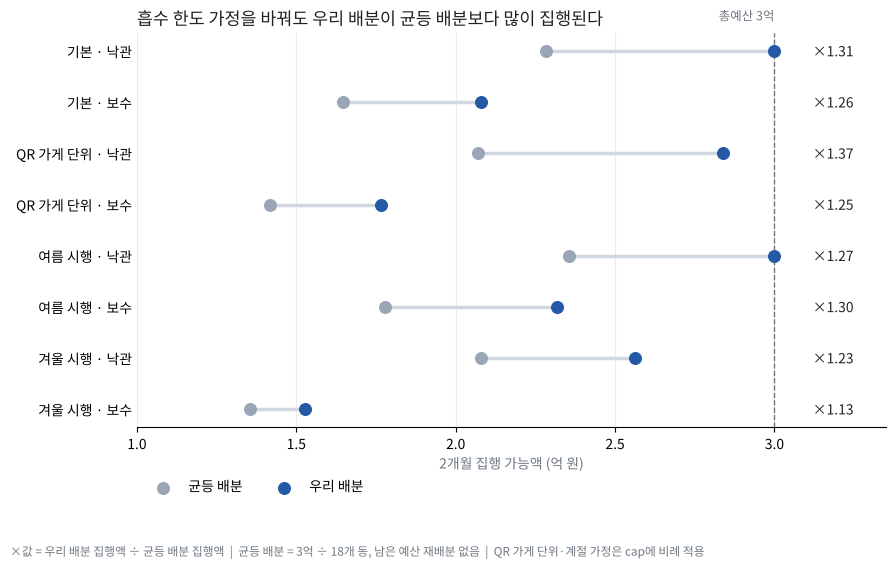

In [ ]:
INK, MUTED, OURS, UNIF = '#1f2328', '#6e7781', '#2459A6', '#9aa6b5'
D = ALC.assign(행=ALC['가정'] + ' · ' + ALC['cap'])[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5.2))
for i, r in D.iterrows():
    ax.plot([r['균등 배분 집행(억)'], r['우리 배분 집행(억)']], [i, i], color='#d0d7de', lw=2.5, zorder=1)
    ax.scatter(r['균등 배분 집행(억)'], i, s=70, color=UNIF, zorder=2, label='균등 배분' if i == 0 else None)
    ax.scatter(r['우리 배분 집행(억)'], i, s=70, color=OURS, zorder=3, label='우리 배분' if i == 0 else None)
    ax.text(3.12, i, f"×{r['우리 ÷ 균등']:.2f}", va='center', fontsize=10, color=INK)
ax.set_yticks(range(len(D))); ax.set_yticklabels(D['행'], fontsize=10)
ax.axvline(TOTAL / 1e8, color=MUTED, lw=1, ls='--'); ax.text(TOTAL / 1e8, len(D) - 0.4, '총예산 3억', ha='right', fontsize=9, color=MUTED)
ax.set_xlim(1.0, 3.35); ax.set_xlabel('2개월 집행 가능액 (억 원)', color=MUTED)
ax.set_title('흡수 한도 가정을 바꿔도 우리 배분이 균등 배분보다 많이 집행된다', loc='left', fontsize=12.5, color=INK)
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.1), ncol=2, frameon=False, fontsize=10)
ax.grid(axis='x', alpha=0.25); ax.set_axisbelow(True)
for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.text(0.01, -0.08, '×값 = 우리 배분 집행액 ÷ 균등 배분 집행액  |  균등 배분 = 3억 ÷ 18개 동, 남은 예산 재배분 없음  |  '
         'QR 가게 단위·계절 가정은 cap에 비례 적용', fontsize=8.5, color=MUTED)
plt.tight_layout(); plt.savefig('4-2_배분결론_민감도.png', dpi=200, bbox_inches='tight'); plt.show()

**해석**
- cap 합계는 가정에 따라 1.5억~5억으로 크게 달라진다 (겨울·보수가 가장 작고 여름·낙관이 가장 큼).
- 그러나 **8개 조합 모두에서 우리 배분이 균등 배분보다 1.13~1.37배 더 집행**된다 → 배분 결론은 가정에 둔감하다.
- 가장 불리한 조건(겨울 시행 + 보수 cap)에서도 우위가 유지된다.

## ③ 참고: 타깃 국적 기준 (1-5)

In [ ]:
first = lambda s: s.split(',')[0].strip()
same_top1 = {c: (NAT[f'타깃_{c}'].map(first) == NAT['타깃_10%'].map(first)).mean() for c in ['5%', '15%']}
same_all  = {c: (NAT[f'타깃_{c}'] == NAT['타깃_10%']).mean() for c in ['5%', '15%']}
print(f"1위 국적 일치: 5% 기준 {same_top1['5%']:.0%}, 15% 기준 {same_top1['15%']:.0%}")
print(f"국적 조합 전체 일치: 5% 기준 {same_all['5%']:.0%}, 15% 기준 {same_all['15%']:.0%}")

## 결론
- **어디에 할인할지(대상 18개 동)는 기준을 바꿔도 거의 유지된다.** 소비갭 기준은 극단값의 영향을 받지 않는 중앙값이 적절하다.
- **우리 배분이 균등 배분보다 많이 집행된다는 결론은 흡수 한도·QR 측정·시행 계절 가정을 모두 바꿔도 유지된다 (1.13~1.37배).**
- 반면 집행 금액(1.5억~3억)과 추가 소비 규모(효과값에 따라 0.9억~6.7억)는 가정에 따라 달라지므로 범위로 제시한다.
- 주 타깃 국적은 기준과 무관하게 유지되며, 2·3순위 국적은 기준에 따라 달라진다.